In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
df = pd.read_csv('Customers_Cleaned.csv')
df.head(10)

,Customer_ID,Home_City,Region,Account_Type,Monthly_Income,Account_Open_Date,KYC_Status,Risk_Rating,Account_Status,Status_Date
0,CUST100003,Bhubaneswar,East,Current,"223,700.00",10-07-2021,Expired,Low,Active,NaN
1,CUST100004,Chennai,South,Savings,"41,400.00",04-07-2018,Verified,Low,Active,NaN
2,CUST100005,Delhi,North,Savings,"75,000.00",31-12-2019,Verified,Low,Active,NaN
3,CUST100006,Nagpur,Central,Savings,"48,300.00",19-04-2019,Verified,Low,Active,NaN
4,CUST100007,Hyderabad,South,Current,"127,200.00",02-01-2015,Pending,Low,Active,NaN
5,CUST100008,Kolkata,East,Savings,"27,600.00",02-05-2019,Verified,Medium,Dormant,17-03-2026
6,CUST100009,Gurugram,North,Savings,"79,900.00",08-10-2020,Verified,Medium,Active,NaN
7,CUST100010,Ahmedabad,West,Savings,"20,500.00",23-09-2012,Pending,Low,Active,NaN
8,CUST100011,Pune,West,Savings,"18,300.00",12-01-2021,Verified,Low,Active,NaN
9,CUST100012,Bhopal,Central,Savings,"51,100.00",31-03-2015,Verified,High,Active,NaN


In [3]:
dt = pd.read_csv('Transactions_Cleaned.csv')
dt.head(10)

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Type,Channel,Location,Account_Type,Merchant_Category,Initiated_By,Approver_ID,Approval_Status,Alert_Flag,Investigation_Status,Fraud_Flag,Reamarks,Transaction_Amount
0,TXN10033058,CUST103278,2026-03-13 21:37:00,Payment,Online,Bengaluru,Savings,Restaurants,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,"4,332.41"
1,TXN10012770,CUST102373,2025-12-03 19:31:16,Payment,Online,Mumbai,Savings,Electronics,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,"3,067.37"
2,TXN10048207,CUST104435,2026-05-27 01:05:03,Withdrawal,ATM,Kolkata,Current,Cash Withdrawal,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,NaN
3,TXN10033254,CUST102180,2026-03-14 20:27:02,Withdrawal,ATM,Nagpur,Savings,Cash Withdrawal,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,"10,000.00"
4,TXN10041140,CUST103438,2026-04-22 17:42:17,Payment,Mobile,Mumbai,Current,Grocery,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,"3,496.37"
5,TXN10047125,CUST102651,2026-05-21 20:26:42,Transfer,Mobile,Nagpur,Current,Business Transfer,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,NaN
6,TXN10030884,CUST102747,2026-03-02 22:49:05,Payment,Online,Jaipur,Savings,Restaurants,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,see ticket,"10,076.54"
7,TXN10070266,CUST100022,2026-09-09 15:08:06,Payment,Net Banking,Pune,Current,Travel,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,"2,665.65"
8,TXN10027003,CUST101261,2026-02-11 10:08:48,Payment,POS,Delhi,Current,Grocery,CUSTOMER,NaN,Not Required,0.00,NaN,0.00,NaN,698.65
9,TXN10001997,CUST101511,2025-10-11 04:54:54,Deposit,Branch,Gurugram,Current,Salary Credit,EMP033,NaN,Not Required,0.00,NaN,NaN,NaN,"115,758.44"


In [4]:
from decimal import Decimal

In [5]:
df['Account_Open_Date'] = pd.to_datetime(df['Account_Open_Date'], format='mixed')
df['Status_Date'] = pd.to_datetime(df['Status_Date'], format='mixed')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Customer_ID        5025 non-null   str           
 1   Home_City          5025 non-null   str           
 2   Region             5025 non-null   str           
 3   Account_Type       5025 non-null   str           
 4   Monthly_Income     4875 non-null   float64       
 5   Account_Open_Date  5005 non-null   datetime64[us]
 6   KYC_Status         5025 non-null   str           
 7   Risk_Rating        5025 non-null   str           
 8   Account_Status     5025 non-null   str           
 9   Status_Date        225 non-null    datetime64[us]
dtypes: datetime64[us](2), float64(1), str(7)
memory usage: 621.0 KB


In [7]:
dt['Transaction_Date'] = pd.to_datetime(dt['Transaction_Date'], format = 'mixed')

In [8]:
dt['Fraud_Flag'].isnull().sum()

np.int64(1920)

In [9]:
dt['Alert_Flag'] = pd.to_numeric(dt['Alert_Flag'], errors='coerce').astype('Int64')
dt['Fraud_Flag'] = pd.to_numeric(dt['Fraud_Flag'], errors='coerce').astype('Int64')

In [60]:
dt.info()

<class 'pandas.DataFrame'>
RangeIndex: 75034 entries, 0 to 75033
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Transaction_ID           75034 non-null  str           
 1   Customer_ID              75004 non-null  str           
 2   Transaction_Date         75009 non-null  datetime64[us]
 3   Transaction_Type         75034 non-null  str           
 4   Channel                  75034 non-null  str           
 5   Location                 75007 non-null  str           
 6   Account_Type             75034 non-null  str           
 7   Merchant_Category        74782 non-null  str           
 8   Initiated_By             75034 non-null  str           
 9   Approver_ID              405 non-null    str           
 10  Approval_Status          75034 non-null  str           
 11  Alert_Flag               72786 non-null  Int64         
 12  Investigation_Status     3163 non-null   st

In [11]:
at = pd.read_csv('location_master.csv')
lm = pd.read_csv('location_master.csv')
mr = pd.read_csv('merchant_categories.csv')

In [12]:
## DATASET FOR CONFIRMED FRAUD ANALYSIS

In [73]:
fraud_data = dt.dropna(subset= ['Fraud_Flag']).copy()
fraud_data

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Type,Channel,Location,Account_Type,Merchant_Category,Initiated_By,Approver_ID,Approval_Status,Alert_Flag,Investigation_Status,Fraud_Flag,Reamarks,Transaction_Amount,Merchant_Category_Clean,Threshold,Threshold_Breach
0,TXN10033058,CUST103278,2026-03-13 21:37:00,Payment,Online,Bengaluru,Savings,Restaurants,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"4,332.41",Restaurants,"100,000.00",False
1,TXN10012770,CUST102373,2025-12-03 19:31:16,Payment,Online,Mumbai,Savings,Electronics,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"3,067.37",Electronics,"100,000.00",False
2,TXN10048207,CUST104435,2026-05-27 01:05:03,Withdrawal,ATM,Kolkata,Current,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,NaN,Not Applicable,"50,000.00",False
3,TXN10033254,CUST102180,2026-03-14 20:27:02,Withdrawal,ATM,Nagpur,Savings,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"10,000.00",Not Applicable,"50,000.00",False
4,TXN10041140,CUST103438,2026-04-22 17:42:17,Payment,Mobile,Mumbai,Current,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"3,496.37",Grocery,"100,000.00",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75029,TXN10057677,CUST101352,2026-07-11 21:41:44,Withdrawal,ATM,Kolkata,Current,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"11,500.00",Not Applicable,"50,000.00",False
75030,TXN10072796,CUST101381,2026-09-20 17:10:58,Payment,POS,AMD,Savings,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,766.51,Grocery,"100,000.00",False
75031,TXN10021585,CUST102678,2026-01-15 16:46:14,Payment,Online,Jaipur,Current,Restaurants,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"12,540.14",Restaurants,"100,000.00",False
75032,TXN10036544,CUST104221,2026-03-30 17:50:45,Payment,Online,Jaipur,Current,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"2,289.27",Grocery,"100,000.00",False


In [62]:
fraud_data.columns

Index(['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Type',
       'Channel', 'Location', 'Account_Type', 'Merchant_Category',
       'Initiated_By', 'Approver_ID', 'Approval_Status', 'Alert_Flag',
       'Investigation_Status', 'Fraud_Flag', 'Reamarks', 'Transaction_Amount',
       'Merchant_Category_Clean', 'Threshold', 'Threshold_Breach'],
      dtype='str')

# Q1. Which transaction channels and transaction types have the highest fraud rate?

In [15]:
channel_analysis = fraud_data.groupby('Channel').agg(
    Total_Transactions=('Fraud_Flag', 'count'),
    Fraud_Transactions=('Fraud_Flag', 'sum'),
    Fraud_Rate=('Fraud_Flag', 'mean')
)

channel_analysis['Fraud_Rate'] = (
    channel_analysis['Fraud_Rate'] * 100
).round(2)

channel_analysis = channel_analysis.sort_values(
    'Fraud_Rate', ascending=False
)

channel_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate
Channel,,,
Online,16452,811,4.93
Net Banking,1394,64,4.59
Branch,11788,273,2.32
Mobile,20564,304,1.48
POS,12157,86,0.71
ATM,10759,71,0.66


# Q2. Which merchant categories contribute the highest fraud exposure?

In [16]:
## Clean Merchant Category

## Step 1: Standardize text

dt['Merchant_Category_Clean'] = (
    dt['Merchant_Category']
    .astype('string')
    .str.strip()
    .str.lower()
)

In [17]:
## Step 2: Create a dictionary for correcting categories

category_mapping = {

    # Grocery
    'grocery': 'Grocery',
    'grocry': 'Grocery',

    # Electronics
    'electronics': 'Electronics',
    'electronic': 'Electronics',
    'electronis': 'Electronics',

    # Restaurants
    'restaurants': 'Restaurants',
    'resturants': 'Restaurants',

    # Jewellery
    'jewellery': 'Jewellery',
    'jewelry': 'Jewellery',

    # Utilities
    'utilities': 'Utilities',
    'utility': 'Utilities',

    # Healthcare
    'healthcare': 'Healthcare',
    'health care': 'Healthcare',

    # Entertainment
    'entertainment': 'Entertainment',
    'entertainmnt': 'Entertainment',

    # Crypto
    'crypto': 'Crypto',
    'crypto exchange': 'Crypto Exchange',
    'crypto exchnage': 'Crypto Exchange',

    # Gambling
    'online gambling': 'Online Gambling',
    'gambling': 'Gambling',

    # Luxury
    'luxury goods': 'Luxury Goods',
    'luxury': 'Luxury Goods',

    # Other categories
    'travel': 'Travel',
    'education': 'Education',
    'fuel': 'Fuel'
}

In [18]:
## Step 3: Apply the mapping

dt['Merchant_Category_Clean'] = (
    dt['Merchant_Category_Clean']
    .replace(category_mapping)
)

In [36]:
## Step 4: Handle non-merchant values and missing values

non_merchant = [
    'cash withdrawal',
    'business transfer',
    'salary credit',
    'cash deposit',
    'peer transfer',
    'cheque deposit'
]

dt['Merchant_Category_Clean'] = (
    dt['Merchant_Category_Clean']
    .replace(non_merchant, 'Not Applicable')
)

dt['Merchant_Category_Clean'] = (
    dt['Merchant_Category_Clean']
    .replace(['unknown', '?'], 'Unknown')
    .fillna('Unknown')
)


In [39]:
dt['Merchant_Category_Clean']

0           Restaurants
1           Electronics
2        Not Applicable
3        Not Applicable
4               Grocery
              ...      
75029    Not Applicable
75030           Grocery
75031       Restaurants
75032           Grocery
75033    Not Applicable
Name: Merchant_Category_Clean, Length: 75034, dtype: string

In [42]:
merchant_data = fraud_data[
    ~fraud_data['Merchant_Category_Clean'].isin(
        ['Unknown', 'Not Applicable']
    )
].copy()

In [43]:
merchant_data['Fraud_Amount'] = (
    merchant_data['Transaction_Amount'] *
    merchant_data['Fraud_Flag']
)

merchant_analysis = merchant_data.groupby(
    'Merchant_Category_Clean'
).agg(
    Total_Transactions=('Fraud_Flag', 'count'),
    Fraud_Transactions=('Fraud_Flag', 'sum'),
    Fraud_Rate=('Fraud_Flag', 'mean'),
    Fraud_Amount=('Fraud_Amount', 'sum')
)

merchant_analysis['Fraud_Rate'] = (
    merchant_analysis['Fraud_Rate'] * 100
).round(2)

merchant_analysis = merchant_analysis.sort_values(
    'Fraud_Amount', ascending=False
)

merchant_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate,Fraud_Amount
Merchant_Category_Clean,,,,
Jewellery,1124,42,3.74,"2,377,686.24"
Crypto Exchange,954,182,19.08,"1,047,486.38"
Electronics,2939,169,5.75,"773,645.66"
Luxury Goods,695,19,2.73,"556,928.02"
Grocery,7570,48,0.63,"326,283.48"
Online Gambling,824,152,18.45,"303,322.39"
Entertainment,2983,148,4.96,"191,233.18"
Fuel,3081,26,0.84,"188,854.84"
Travel,3102,19,0.61,"171,908.89"


# Q3. Which geographical locations have the highest concentration of fraudulent transactions?

In [57]:
pd.DataFrame(fraud_data['Location_Clean'].unique())

,0
0,Bengaluru
1,Mumbai
2,Kolkata
3,Nagpur
4,Jaipur
5,Pune
6,Delhi
7,Gurugram
8,Hyderabad
9,Bhubaneswar


In [45]:
fraud_data['Location'].astype('string').str.strip().str.lower().copy

<bound method NDFrame.copy of 0        bengaluru
1           mumbai
2          kolkata
3           nagpur
4           mumbai
           ...    
75029      kolkata
75030          amd
75031       jaipur
75032       jaipur
75033        delhi
Name: Location, Length: 73114, dtype: string>

In [46]:
fraud_data['Location_Clean'] = fraud_data['Location'].astype('string').str.strip().str.lower()

In [47]:
location_mapping = {
    "bengaluru": "Bengaluru",
    "bengalore": "Bengaluru",
    "bangalore": "Bengaluru",

    "mumbai": "Mumbai",
    "mumbi": "Mumbai",
    "bombay": "Mumbai",

    "kolkata": "Kolkata",
    "calcutta": "Kolkata",

    "nagpur": "Nagpur",

    "jaipur": "Jaipur",

    "pune": "Pune",
    "poona": "Pune",

    "delhi": "Delhi",
    "new delhi": "Delhi",

    "gurugram": "Gurugram",
    "gurgaon": "Gurugram",

    "hyderabad": "Hyderabad",
    "hyderbad": "Hyderabad",
    "hyd": "Hyderabad",

    "bhubaneswar": "Bhubaneswar",
    "bhubaneshwar": "Bhubaneswar",

    "indore": "Indore",

    "ahmedabad": "Ahmedabad",
    "ahmadabad": "Ahmedabad",
    "amd": "Ahmedabad",

    "bhopal": "Bhopal",

    "chennai": "Chennai",
    "madras": "Chennai"
}

In [48]:
fraud_data['Location_Clean'] = fraud_data['Location_Clean'].replace(location_mapping)

In [49]:
fraud_data['Location_Clean'] = fraud_data['Location_Clean'].replace(['<NA>','unknown','???'], 'Unknown').fillna('Unknown')

In [50]:
pd.DataFrame(fraud_data['Location_Clean'].unique())

,0
0,Bengaluru
1,Mumbai
2,Kolkata
3,Nagpur
4,Jaipur
5,Pune
6,Delhi
7,Gurugram
8,Hyderabad
9,Bhubaneswar


In [51]:
fraud_data.drop(columns = 'Location', inplace = True)

In [52]:
fraud_data.columns

Index(['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Type',
       'Channel', 'Account_Type', 'Merchant_Category', 'Initiated_By',
       'Approver_ID', 'Approval_Status', 'Alert_Flag', 'Investigation_Status',
       'Fraud_Flag', 'Reamarks', 'Transaction_Amount',
       'Merchant_Category_Clean', 'Location_Clean'],
      dtype='str')

In [53]:
geographical_data = fraud_data[~fraud_data['Location_Clean'].isin(['Unknown'])].copy()

In [54]:
geographical_data

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Type,Channel,Account_Type,Merchant_Category,Initiated_By,Approver_ID,Approval_Status,Alert_Flag,Investigation_Status,Fraud_Flag,Reamarks,Transaction_Amount,Merchant_Category_Clean,Location_Clean
0,TXN10033058,CUST103278,2026-03-13 21:37:00,Payment,Online,Savings,Restaurants,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"4,332.41",Restaurants,Bengaluru
1,TXN10012770,CUST102373,2025-12-03 19:31:16,Payment,Online,Savings,Electronics,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"3,067.37",Electronics,Mumbai
2,TXN10048207,CUST104435,2026-05-27 01:05:03,Withdrawal,ATM,Current,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,NaN,Not Applicable,Kolkata
3,TXN10033254,CUST102180,2026-03-14 20:27:02,Withdrawal,ATM,Savings,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"10,000.00",Not Applicable,Nagpur
4,TXN10041140,CUST103438,2026-04-22 17:42:17,Payment,Mobile,Current,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"3,496.37",Grocery,Mumbai
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75029,TXN10057677,CUST101352,2026-07-11 21:41:44,Withdrawal,ATM,Current,Cash Withdrawal,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"11,500.00",Not Applicable,Kolkata
75030,TXN10072796,CUST101381,2026-09-20 17:10:58,Payment,POS,Savings,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,766.51,Grocery,Ahmedabad
75031,TXN10021585,CUST102678,2026-01-15 16:46:14,Payment,Online,Current,Restaurants,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"12,540.14",Restaurants,Jaipur
75032,TXN10036544,CUST104221,2026-03-30 17:50:45,Payment,Online,Current,Grocery,CUSTOMER,NaN,Not Required,0,NaN,0,NaN,"2,289.27",Grocery,Jaipur


In [55]:
geographical_data['Fraud_Amount'] = geographical_data['Transaction_Amount']*geographical_data['Fraud_Flag']

location_analysis = geographical_data.groupby('Location_Clean').agg(
    Total_Transactions = ('Fraud_Flag','count'),
    Fraud_Transactions = ('Fraud_Flag', 'sum'),
    Fraud_Rate = ('Fraud_Flag' ,'mean'),
    Fraud_Amount = ('Fraud_Amount', 'sum'))

location_analysis['Fraud_Rate'] = (
    location_analysis['Fraud_Rate'] * 100
).round(2)

location_analysis = location_analysis.sort_values(
    'Fraud_Amount', ascending=False
)

location_analysis
    

,Total_Transactions,Fraud_Transactions,Fraud_Rate,Fraud_Amount
Location_Clean,,,,
Mumbai,10042,333,3.32,"12,405,773.79"
Chennai,6392,139,2.17,"12,082,906.79"
Pune,5053,174,3.44,"10,365,658.94"
Kolkata,5361,65,1.21,"8,765,311.34"
Hyderabad,6065,117,1.93,"7,639,475.02"
Delhi,9369,115,1.23,"7,037,152.15"
Bengaluru,8918,101,1.13,"6,394,323.93"
Bhubaneswar,2306,66,2.86,"4,110,992.79"
Ahmedabad,4622,173,3.74,"3,769,678.19"


# Q4. Are transactions exceeding approval thresholds being properly approved?

In [86]:
# ==========================================
# TRANSACTION THRESHOLD ANALYSIS
# ==========================================

# Step 1: Clean Transaction Type
fraud_data['Transaction_Type_Clean'] = (
    fraud_data['Transaction_Type']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Step 2: Standardize inconsistent transaction names
transaction_mapping = {
    'fund transfer': 'transfer',
    'fundtransfer': 'transfer'
}

fraud_data['Transaction_Type_Clean'] = (
    fraud_data['Transaction_Type_Clean']
    .replace(transaction_mapping)
    .str.title()
)

# Step 3: Define transaction thresholds
thresholds = {
    'Transfer': 200000,
    'Withdrawal': 50000,
    'Payment': 100000,
    'Deposit': 500000
}

# Step 4: Assign threshold to each transaction
fraud_data['Threshold'] = (
    fraud_data['Transaction_Type_Clean']
    .map(thresholds)
)

# Step 5: Identify threshold breaches
fraud_data['Threshold_Breach'] = (
    fraud_data['Transaction_Amount'] >
    fraud_data['Threshold']
)

# Step 6: Generate statistical summary
threshold_stats = fraud_data.groupby(
    'Transaction_Type_Clean'
).agg(
    Total_Transactions=('Transaction_ID', 'count'),
    Threshold=('Threshold', 'first'),
    Total_Breaches=('Threshold_Breach', 'sum'),
    Average_Amount=('Transaction_Amount', 'mean'),
    Median_Amount=('Transaction_Amount', 'median'),
    Maximum_Amount=('Transaction_Amount', 'max'),
    Minimum_Amount=('Transaction_Amount', 'min')
).reset_index()

# Step 7: Calculate breach percentage
threshold_stats['Breach_Percentage'] = (
    threshold_stats['Total_Breaches'] /
    threshold_stats['Total_Transactions'] * 100
).round(2)

# Step 8: Round statistical values
threshold_stats = threshold_stats.round(2)

# Step 9: Rename column for presentation
threshold_stats = threshold_stats.rename(
    columns={'Transaction_Type_Clean': 'Transaction_Type'}
)

# Step 10: Display final dataframe
threshold_stats

,Transaction_Type,Total_Transactions,Threshold,Total_Breaches,Average_Amount,Median_Amount,Maximum_Amount,Minimum_Amount,Breach_Percentage
0,Deposit,9175,500000,95,"71,551.71","23,825.42","18,361,529.00","-50,347.93",1.04
1,Payment,35875,100000,68,"6,632.98","2,616.97","12,197,014.00","-56,522.19",0.19
2,Transfer,15450,200000,195,"36,583.92","11,716.28","9,999,999.00","-86,066.45",1.26
3,Withdrawal,12614,50000,43,"10,954.92","7,000.00","1,700,000.00","-33,500.00",0.34


# Q5. How big is the fraud problem?

Fraud rate: 2.20% | Fraud value: 88,398,053


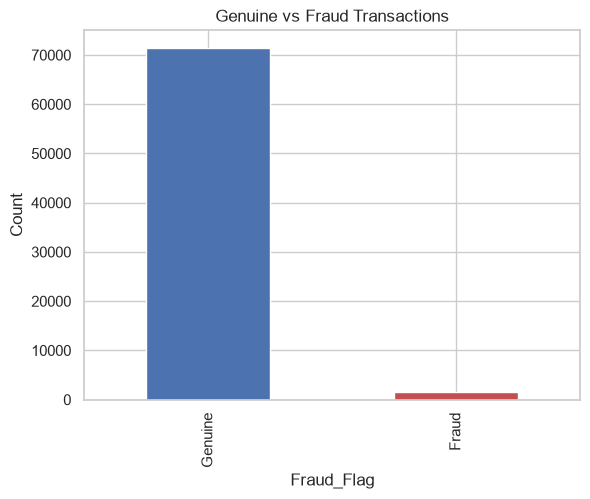

In [94]:
total_txn = len(fraud_data)
fraud_txn = fraud_data["Fraud_Flag"].sum()
fraud_rate = fraud_txn / total_txn * 100
fraud_value = fraud_data.loc[fraud_data["Fraud_Flag"]==1, "Transaction_Amount"].sum()
print(f"Fraud rate: {fraud_rate:.2f}% | Fraud value: {fraud_value:,.0f}")

fraud_data["Fraud_Flag"].map({0:"Genuine",1:"Fraud"}).value_counts().plot(
    kind="bar", color=["#4C72B0","#C44E52"], title="Genuine vs Fraud Transactions")
plt.ylabel("Count"); plt.show()

In [95]:
# Export fraud_data to CSV
fraud_data.to_csv("fraud_data.csv", index=False)

# Download confirmation
print("fraud_data.csv exported successfully!")

fraud_data.csv exported successfully!
